# Experimento — IDS multiclasse para SOME/IP (C1)

Notebook **autossuficiente** e **apresentável**: roda o experimento ponta a ponta
importando o código de `src/` (fonte única). Etapas:
1. Ambiente/máquina · 2. Dados (PCAPs) · 3. Detecção (acurácia + ablação 12×16)
· 4. Latência por estágio (1 núcleo) · 5. Varredura de cota de CPU · 6. Resumo.

Roda em CPU (ECU-like) ou GPU; os números de latência devem ser lidos em CPU, 1 núcleo.


In [1]:
# --- Bootstrap: garante repo + deps + src no path (funciona local, VM ou Colab) ---
import os, sys
REPO = "someip-ids-multiclass-contentext"
def in_repo(): return os.path.exists("run_experiment.py") and os.path.isdir("src")
if not in_repo() and os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")
if not in_repo() and os.path.isdir(REPO): os.chdir(REPO)
if not in_repo():
    os.system("git lfs install; git clone https://github.com/GuilhermeFrick/%s.git" % REPO)
    os.chdir(REPO)
os.system("%s -m pip install -q -r requirements.txt pandas" % sys.executable)
sys.path.insert(0, os.path.join(os.getcwd(), "src"))
MAX_PACKETS = None      # None = dataset completo (14.2M); use ex. 50000 p/ um teste rápido
print("cwd:", os.getcwd(), "| repo ok:", in_repo(), "| MAX_PACKETS:", MAX_PACKETS)


cwd: /home/ubuntu/someip-ids-multiclass-contentext | repo ok: True | MAX_PACKETS: None


## 1. Ambiente / máquina


In [2]:
import pipeline
MACHINE = pipeline.machine_info()
for k, v in MACHINE.items(): print(f"{k:14}: {v}")
DEVICE = "cuda" if __import__("shutil").which("nvidia-smi") else "cpu"
print("device        :", DEVICE)


platform      : Linux-6.17.0-1017-aws-x86_64-with-glibc2.39
processor     : x86_64
cpu_logical   : 8
cpu_physical  : 8
ram_gb        : 16.4
device        : cpu


## 2. Dados — PCAPs do dataset (figshare)
Tráfego SOME/IP normal + 4 cenários de ataque (DoS, Fuzzy, MITM single/multi), ~14,2 M pacotes.


In [3]:
if not os.path.exists("data/pcap/benign_traffic.pcap"):
    print("baixando PCAPs (~1.9 GB)..."); os.system("%s scripts/download_pcaps.py" % sys.executable)
print(sorted(os.listdir("data/pcap")) if os.path.isdir("data/pcap") else "AUSENTE")


['benign_traffic.pcap', 'dos_noti_flood.pcap', 'fuzzy_sd_offer_rand_noti(1).pcap', 'fuzzy_sd_offer_rand_noti(2).pcap', 'fuzzy_sd_offer_rand_noti(3).pcap', 'mitm_multi_attacker.pcap', 'mitm_single_attacker.pcap']


## 3. Detecção (acurácia)
Extração das 16 features (sem cabeçalho) do PCAP cru → split **temporal** 70/30 →
XGBoost `multi:softprob` (5 classes) → métricas por classe + macro-F1 + **ablação 12×16**.
Salva `results/metrics_temporal.json` + figuras + artefatos (modelo/byte-models/min-max).


In [4]:
OUT = pipeline.run(pcap_dir="data/pcap", out_dir="results", device=DEVICE,
                   n_jobs=-1, make_figs=True, max_packets=MAX_PACKETS)
m, ab = OUT["model_16feat"], OUT["ablation_12feat"]
print("macro-F1  16feat =", round(m["macro_f1"], 4),
      "| 12feat (ablação) =", round(ab["macro_f1"], 4),
      "| accuracy =", round(m["accuracy"], 4))


macro-F1  16feat = 0.964 | 12feat (ablação) = 0.7793 | accuracy = 0.9884


In [5]:
# Tabela por classe (16 feat) + ablação (F1 12 vs 16)
import pandas as pd
rows = []
for c in pipeline.CLASSES:
    pc = m["per_class"][c]
    rows.append({"classe": c, "precision": pc["precision"], "recall": pc["recall"],
                 "F1 (16 feat)": pc["f1-score"], "F1 (12 feat)": ab["per_class_f1"][c]})
pd.DataFrame(rows).round(4)


,classe,precision,recall,F1 (16 feat),F1 (12 feat)
0,normal,0.9998,0.9873,0.9935,0.9746
1,dos,0.9937,0.9993,0.9965,0.8572
2,fuzzy,0.9984,0.9992,0.9988,0.5450
3,mitm_single,0.9862,1.0000,0.9930,0.9423
4,mitm_multi,0.7260,0.9908,0.8380,0.5771


### Figuras (matriz de confusão, ROC/PR, importância das features)


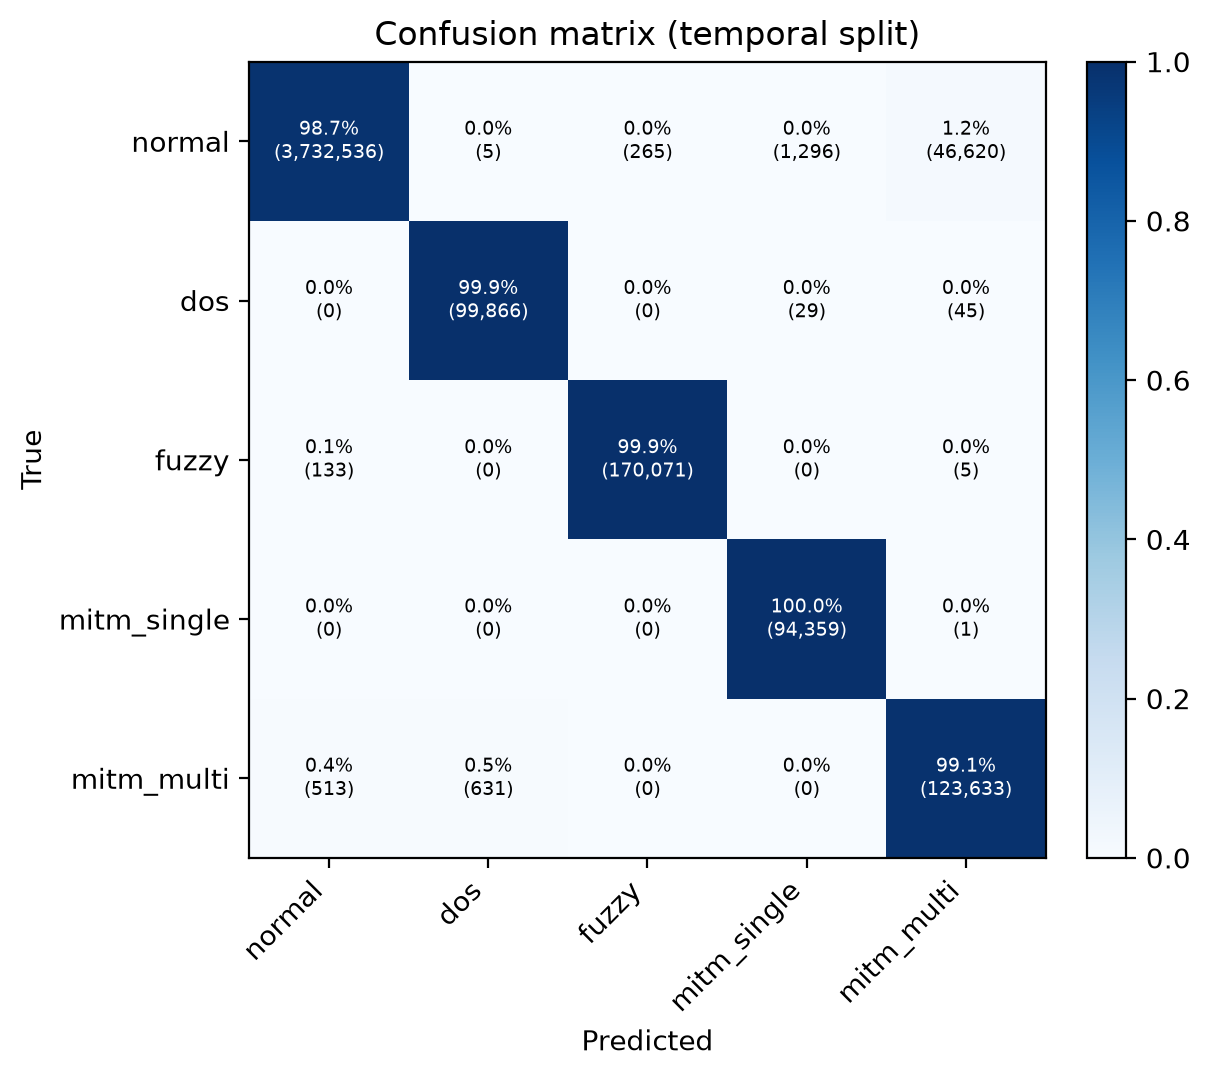

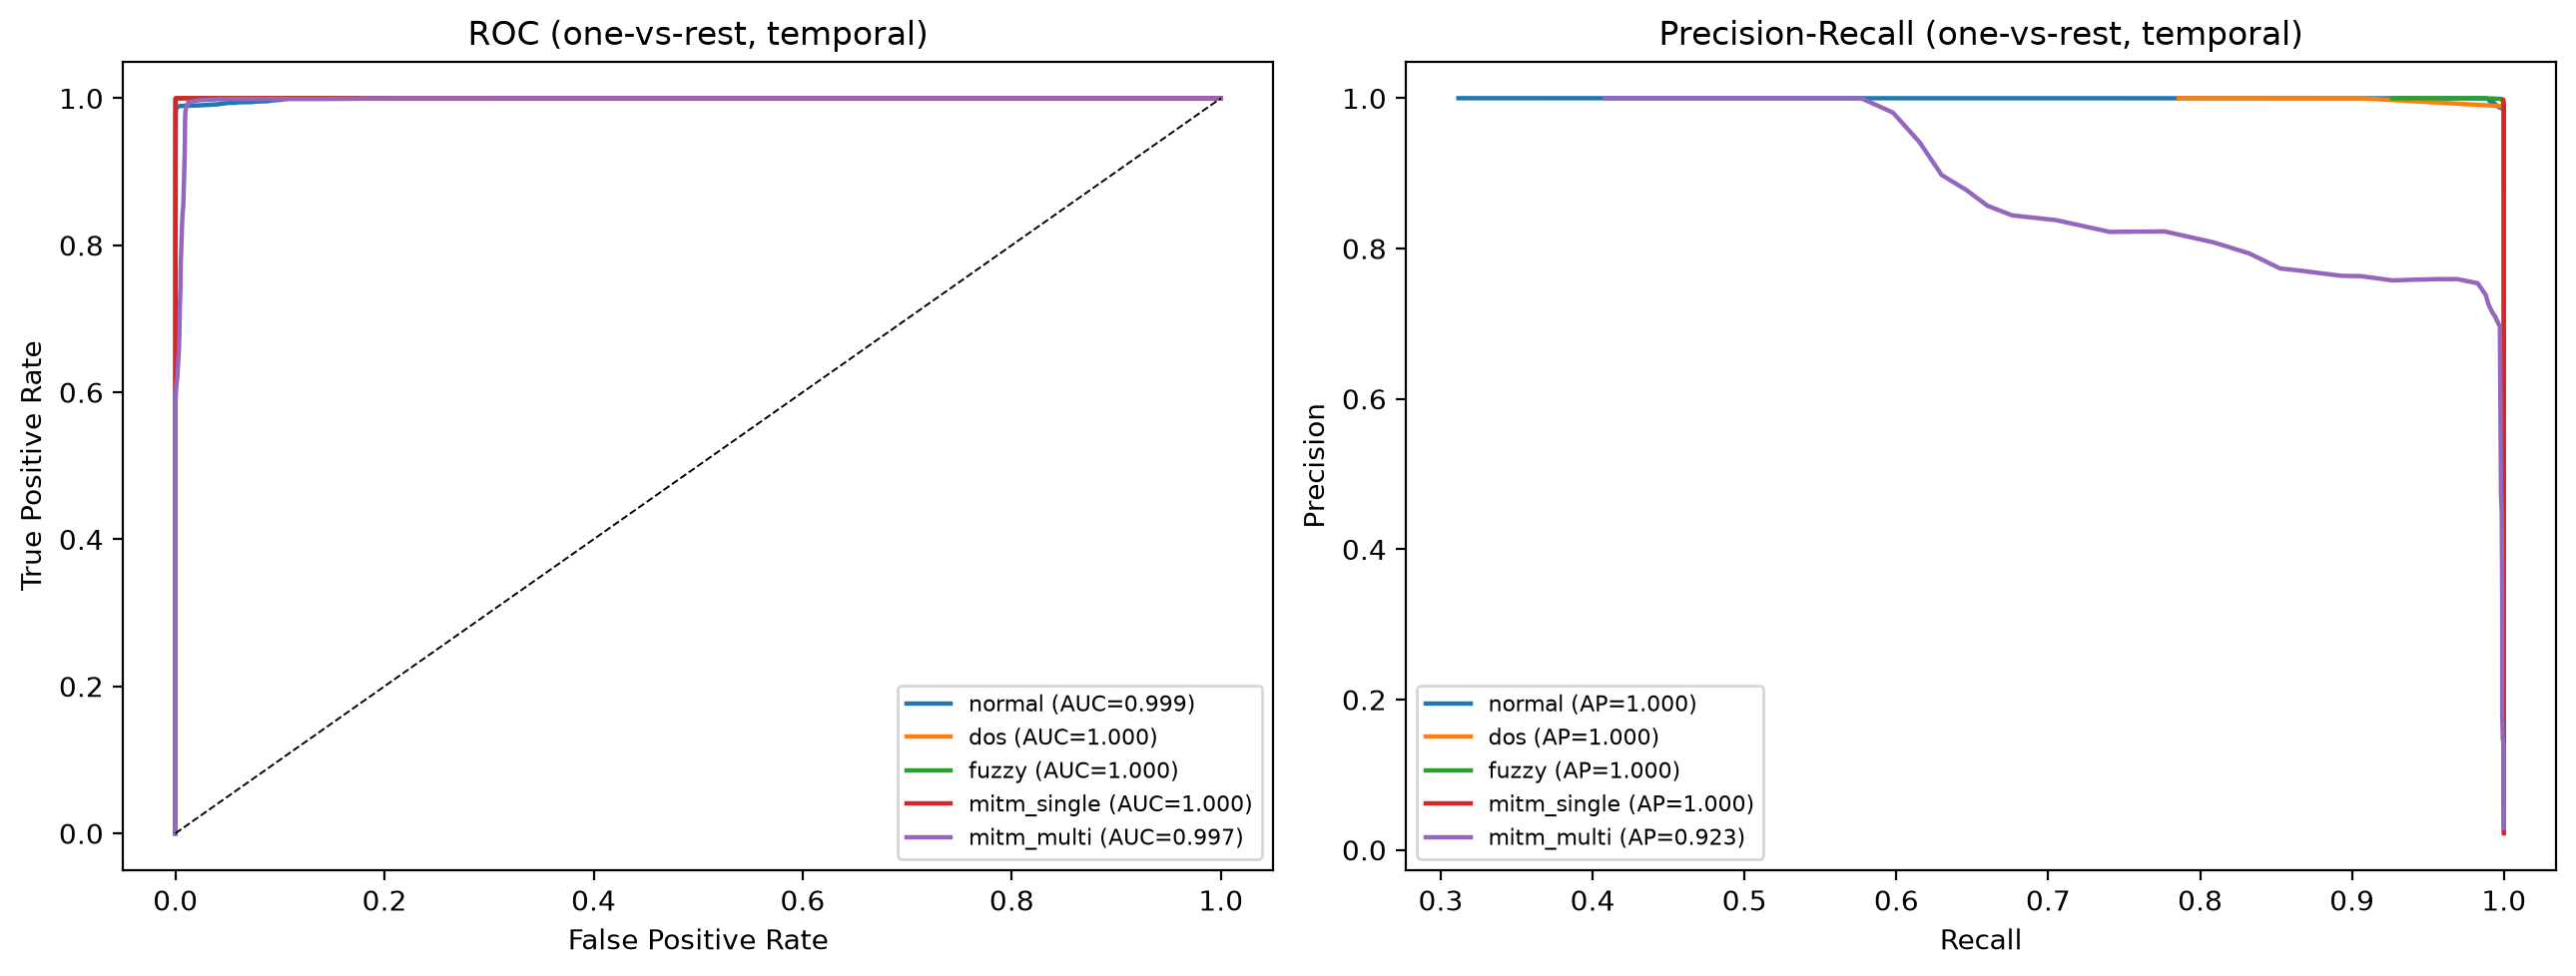

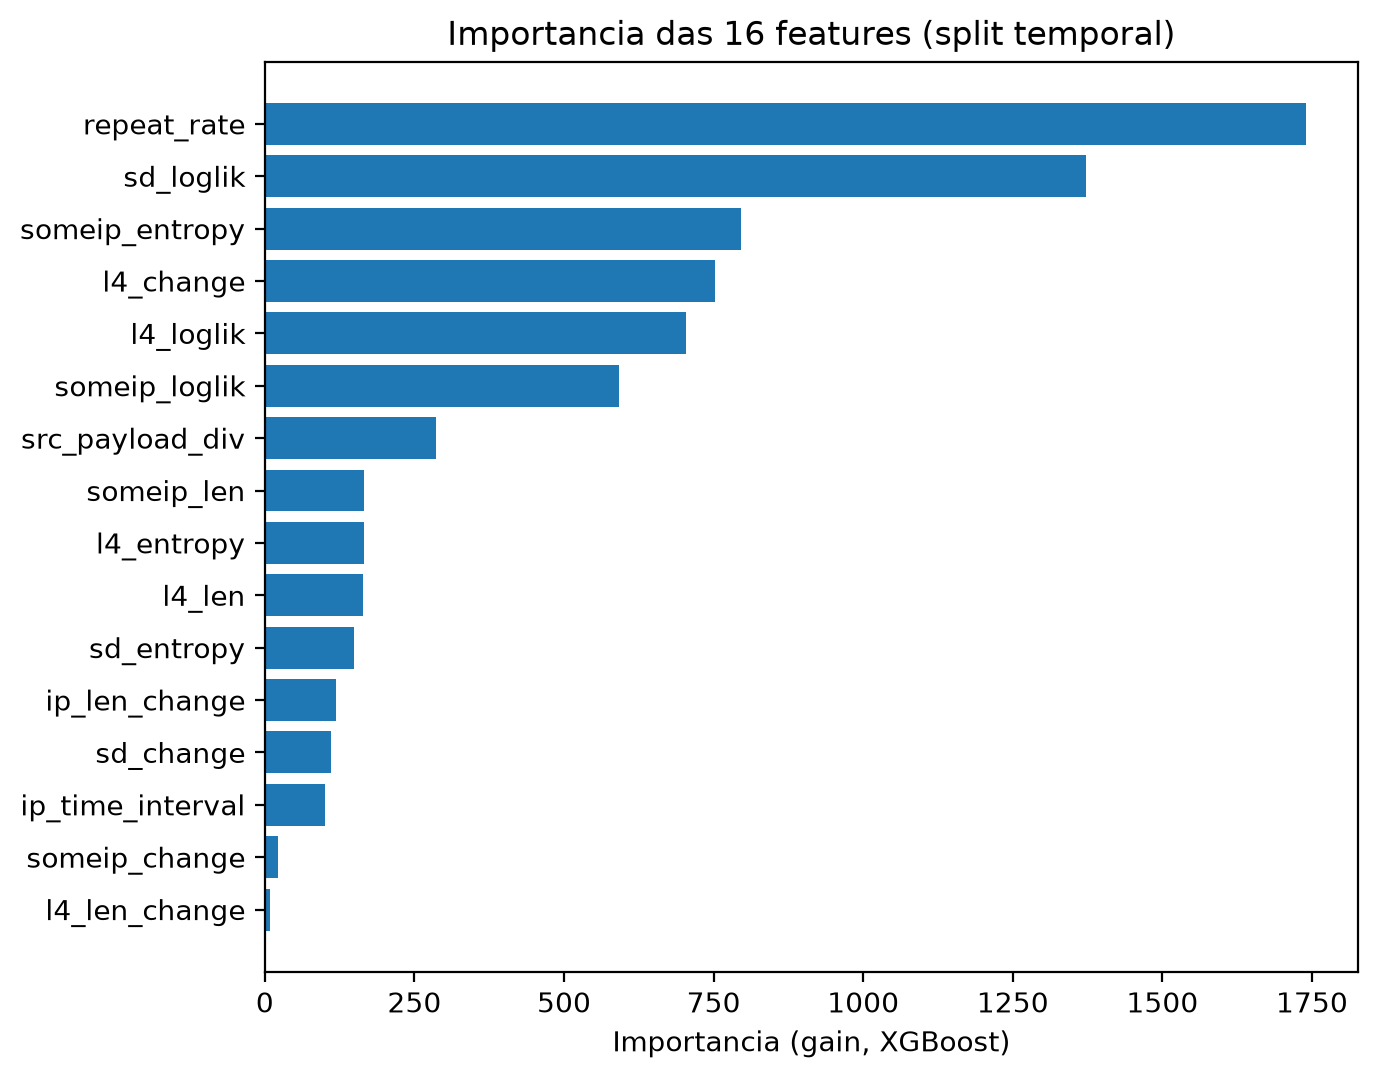

In [6]:
from IPython.display import Image, display
for png in ("cm_temporal.png", "roc_pr_temporal.png", "feature_importance.png"):
    p = os.path.join("results", png)
    if os.path.exists(p): display(Image(filename=p))


## 4. Latência por estágio (1 núcleo, por pacote)
Mede, pacote a pacote, os 4 estágios (layer → feature → classification → decision),
amostrando pacotes (estilo Kim). Classificação medida de 2 formas: `inplace_predict`
(realista) e `predict_proba` (referência do wrapper). Compara com o lote amortizado.


In [7]:
import latency, json, numpy as np
from bytemodel import ByteModel
from extract import L
from xgboost import XGBClassifier

d = np.load("results/bytemodels.npz")
def _bm(k, arr):
    bm = ByteModel(L[k]); bm.logP = arr; return bm
MODELS = {k: _bm(k, d[k]) for k in ("someip", "sd", "l4")}
MMX = np.load("results/minmax.npy"); CIDX = json.load(open("results/content_idx.json"))
CLF = XGBClassifier(); CLF.load_model("results/model_16.json")

LAT = latency.measure("data/pcap/benign_traffic.pcap", MODELS, CLF, CIDX, (MMX[0], MMX[1]),
                      n_samples=1000, warmup=2000)
json.dump(LAT, open("results/latency_sample.json", "w"), indent=2)
s = LAT["stages_us"]
import pandas as pd
tbl = pd.DataFrame([
    {"estágio": "layer (parse)",          "us/pkt": s["layer"]["mean_us"]},
    {"estágio": "feature",                "us/pkt": s["feature"]["mean_us"]},
    {"estágio": "classification (inplace)", "us/pkt": s["classification_inplace"]["mean_us"]},
    {"estágio": "classification (wrapper)", "us/pkt": s["classification_wrapper"]["mean_us"]},
    {"estágio": "decision (argmax)",      "us/pkt": s["decision"]["mean_us"]},
]).round(2)
print("end-to-end: %.1f us/pkt (%.0f pps) | extração %.1f | inferência %.1f us/pkt"
      % (LAT["end_to_end_us_per_pkt"], LAT["throughput_pps"],
         LAT["extraction_us_per_pkt"], LAT["inference_us_per_pkt"]))
print("inferência em LOTE (amortizada): %.2f us/pkt" % OUT["timing"]["inference_us_per_pkt"])
tbl


end-to-end: 386.4 us/pkt (2588 pps) | extração 19.7 | inferência 366.6 us/pkt
inferência em LOTE (amortizada): 2.60 us/pkt


,estágio,us/pkt
0,layer (parse),2.70
1,feature,17.04
2,classification (inplace),365.33
3,classification (wrapper),397.98
4,decision (argmax),1.31


## 5. Varredura de cota de CPU — 1 núcleo (Tabela 5, estilo Kim)
Pin em 1 núcleo + cota de CPU variável (`systemd-run`). Requer `sudo`/systemd (roda na VM;
em Colab pode não estar disponível).


In [8]:
import os, json
os.system("bash scripts/cpu_quota.sh")
QPATH = "results/latency_quota.json"
if os.path.exists(QPATH):
    Q = json.load(open(QPATH))
    import pandas as pd
    dfq = pd.DataFrame([{"cota %": r["cpu_quota_pct"], "cpus": r["allowed_cpus"],
                         "e2e us/pkt": round(r["latency"]["end_to_end_us_per_pkt"], 1),
                         "pps": round(r["latency"]["throughput_pps"])} for r in Q])
    display(dfq)
else:
    print("varredura indisponível (sem systemd/sudo) — rode na VM.")


>> cota 5%  (AllowedCPUs=0)


>> cota 10%  (AllowedCPUs=0)


>> cota 15%  (AllowedCPUs=0)


>> cota 20%  (AllowedCPUs=0)


>> cota 25%  (AllowedCPUs=0)


...

>> cota 200%  (AllowedCPUs=0-1)


>> cota 400%  (AllowedCPUs=0-3)


>> cota 800%  (AllowedCPUs=0-7)


salvo: results/latency_quota.json


,cota %,cpus,e2e us/pkt,pps
0,5,0,20507.5,49
1,10,0,8793.3,114
2,15,0,5236.2,191
3,20,0,4017.7,249
4,25,0,2945.9,339
5,30,0,2643.8,378
6,35,0,2210.2,452
7,40,0,1756.9,569
8,45,0,1794.8,557
9,50,0,1181.3,847


In [9]:
# Curva latência x cota (1 núcleo)
if os.path.exists(QPATH):
    import matplotlib.pyplot as plt
    q1 = [r for r in Q if r["allowed_cpus"] == "0"]
    xs = [r["cpu_quota_pct"] for r in q1]
    ys = [r["latency"]["end_to_end_us_per_pkt"] for r in q1]
    plt.figure(figsize=(7, 4)); plt.plot(xs, ys, "o-")
    plt.xlabel("Cota de CPU (%) — 1 núcleo"); plt.ylabel("Latência end-to-end (us/pacote)")
    plt.title("Latência x cota de CPU (1 núcleo)"); plt.grid(True, alpha=0.3); plt.tight_layout()
    plt.savefig("results/latency_quota.png", dpi=200, bbox_inches="tight"); plt.show()


## 6. Resumo


In [10]:
print("=== DETECÇÃO (split temporal) ===")
print("  macro-F1 16 feat :", round(m["macro_f1"], 4))
print("  macro-F1 12 feat :", round(ab["macro_f1"], 4), "(ablação)")
print("  accuracy         :", round(m["accuracy"], 4))
print("=== LATÊNCIA (1 núcleo, por pacote) ===")
print("  extração         : %.1f us/pkt" % LAT["extraction_us_per_pkt"])
print("  inferência       : %.1f us/pkt (chamada unitária)" % LAT["inference_us_per_pkt"])
print("  end-to-end       : %.1f us/pkt (%.0f pps)" % (LAT["end_to_end_us_per_pkt"], LAT["throughput_pps"]))
print("  inferência lote  : %.2f us/pkt (amortizada)" % OUT["timing"]["inference_us_per_pkt"])
print("Artefatos em results/: metrics_temporal.json, latency_sample.json, latency_quota.json, *.png")


=== DETECÇÃO (split temporal) ===
  macro-F1 16 feat : 0.964
  macro-F1 12 feat : 0.7793 (ablação)
  accuracy         : 0.9884
=== LATÊNCIA (1 núcleo, por pacote) ===
  extração         : 19.7 us/pkt
  inferência       : 366.6 us/pkt (chamada unitária)
  end-to-end       : 386.4 us/pkt (2588 pps)
  inferência lote  : 2.60 us/pkt (amortizada)
Artefatos em results/: metrics_temporal.json, latency_sample.json, latency_quota.json, *.png
